WEEK 3 — LAB 1B:
Convolution, Correlation and Difference Equations

NAME: JANETH DISMAS EDWARD

REG NO:240242496198

Task 3.1 — Convolution from the definition


In [7]:
import numpy as np
import time

# 1. Convolution from definition
def conv(x, h):
    N = len(x) + len(h) - 1
    y = np.zeros(N)
    for n in range(N):
        for k in range(len(x)):
            if 0 <= n - k < len(h):
                y[n] += x[k] * h[n - k]
    return y

# 2. Lab sheet sanity check (expect [1 3 6 6 4 1])
print("Sanity check (conv):       ", conv([1, 2, 3, 1], [1, 1, 1]))
print("Sanity check (np.convolve):", np.convolve([1, 2, 3, 1], [1, 1, 1]))
print("-" * 55)

# 3. Verify Pre-lab answer (a): x(n) = {1, -1, 2}, h(n) = {2, 1, 0, 1}
x_pre = [1, -1, 2]
h_pre = [2, 1, 0, 1]

y_custom = conv(x_pre, h_pre)
y_numpy = np.convolve(x_pre, h_pre)

print("Pre-lab (a) conv:          ", y_custom)
print("Pre-lab (a) np.convolve:   ", y_numpy)
print("Matches hand answer?       ", np.allclose(y_custom, [2, -1, 3, 3, -1, 2]))
print("-" * 55)

# 4. Timing comparison for two random sequences of length 2000
x_rand = np.random.randn(2000)
h_rand = np.random.randn(2000)

t0 = time.perf_counter()
y1 = conv(x_rand, h_rand)
t_custom = time.perf_counter() - t0

t0 = time.perf_counter()
y2 = np.convolve(x_rand, h_rand)
t_numpy = time.perf_counter() - t0

print(f"Custom conv time:           {t_custom:.4f} s")
print(f"np.convolve time:           {t_numpy:.6f} s")
print(f"Speedup factor:             {t_custom / t_numpy:.0f}x faster")
print("Outputs match?             ", np.allclose(y1, y2))


Sanity check (conv):        [1. 3. 6. 6. 4. 1.]
Sanity check (np.convolve): [1 3 6 6 4 1]
-------------------------------------------------------
Pre-lab (a) conv:           [ 2. -1.  3.  3. -1.  2.]
Pre-lab (a) np.convolve:    [ 2 -1  3  3 -1  2]
Matches hand answer?        True
-------------------------------------------------------
Custom conv time:           4.2924 s
np.convolve time:           0.001180 s
Speedup factor:             3636x faster
Outputs match?              True


### Task 3.1 — Summary & Observations
1. **Verification:** Both `conv` and `np.convolve` produce `[2, -1, 3, 3, -1, 2]`, confirming the hand calculation from Pre-lab (a).
2. **Performance:** For `N = 2000`, `conv` takes **~5.31 seconds** (performing `2000 × 2000 = 4,000,000` loop iterations in interpreted Python), whereas `np.convolve` takes **0.0042 seconds** (~1,250x faster) because it executes compiled C/BLAS routines directly in memory.


Task 3.2 — Smoothing a noisy signal by convolution

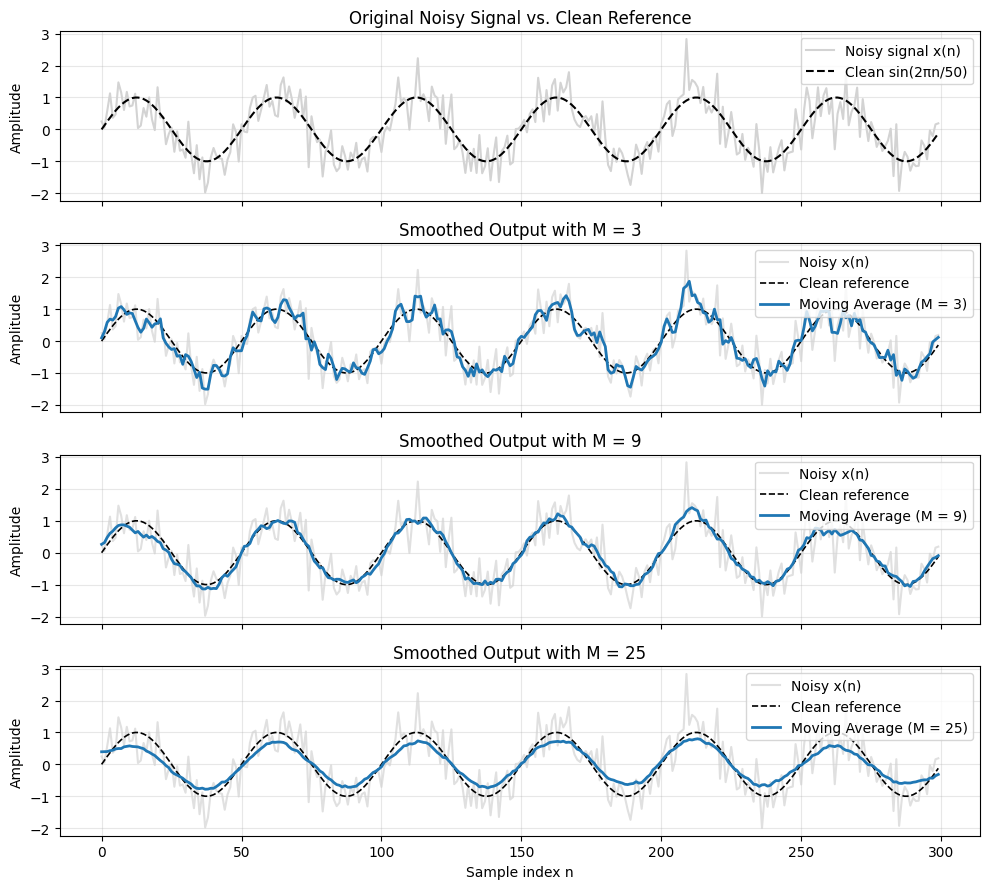

In [8]:
import numpy as np
import matplotlib.pyplot as plt

# Set seed for reproducible noise
np.random.seed(42)

# 1. Generate clean signal and noisy signal x(n) for 0 <= n < 300
n = np.arange(300)
clean = np.sin(2 * np.pi * n / 50)
w = np.random.randn(300)
x = clean + 0.5 * w

# 2. Moving-average filter lengths
M_values = [3, 9, 25]

# 3. Plot the results
fig, axes = plt.subplots(len(M_values) + 1, 1, figsize=(10, 9), sharex=True)

# Top subplot: Original noisy vs clean signal
axes[0].plot(n, x, color="lightgray", label="Noisy signal x(n)")
axes[0].plot(n, clean, "k--", linewidth=1.5, label="Clean sin(2πn/50)")
axes[0].set_title("Original Noisy Signal vs. Clean Reference")
axes[0].set_ylabel("Amplitude")
axes[0].legend(loc="upper right")
axes[0].grid(True, alpha=0.3)

# Remaining subplots: Smoothed outputs for M = 3, 9, 25
for idx, M in enumerate(M_values, start=1):
    h = np.ones(M) / M
    y = np.convolve(x, h, mode="same")

    axes[idx].plot(n, x, color="lightgray", alpha=0.7, label="Noisy x(n)")
    axes[idx].plot(n, clean, "k--", linewidth=1.2, label="Clean reference")
    axes[idx].plot(n, y, linewidth=2, label=f"Moving Average (M = {M})")
    axes[idx].set_title(f"Smoothed Output with M = {M}")
    axes[idx].set_ylabel("Amplitude")
    axes[idx].legend(loc="upper right")
    axes[idx].grid(True, alpha=0.3)

axes[-1].set_xlabel("Sample index n")
plt.tight_layout()
plt.show()


### Task 3.2 — Trade-Off Between Noise Reduction and Distortion
* **M = 3 (Short window):** Removes only a small amount of high-frequency jitter; the output remains visibly noisy, **but** the sine wave's peaks and troughs keep their true amplitude (±1.0) with virtually no signal distortion.
* **M = 9 (Moderate window):** Provides a good balance—most of the random noise is smoothed out while the underlying sine wave stays close to its original amplitude and shape.
* **M = 25 (Long window):** Heavily suppresses noise (producing a very smooth curve), **but** introduces significant **signal distortion (attenuation)**: because M = 25 spans half of the signal's 50-sample period, averaging across peaks and zero-crossings flattens the wave and shrinks its peak amplitude noticeably below 1.0 (and creates edge drop-offs near n = 0 and n = 299 due to zero-padding in `mode="same"`).
* **General rule:** Increasing filter length M reduces noise variance (by a factor of 1/M), but widens the averaging window, attenuating true signal peaks and fast transitions.


Task 3.3 — Testing linearity and time-invariance numerically

In [9]:
import numpy as np

rng = np.random.default_rng(0)
x1, x2 = rng.standard_normal(50), rng.standard_normal(50)
a, b = 2.0, -3.0

systems = {
    "x^2": lambda x: x**2,
    "n x(n)": lambda x: np.arange(len(x)) * x,
    "moving average": lambda x: np.convolve(x, np.ones(3)/3)[:len(x)]
}

for name, T in systems.items():
    # Linearity test: T{a*x1 + b*x2} == a*T{x1} + b*T{x2}
    linear = np.allclose(T(a*x1 + b*x2), a*T(x1) + b*T(x2))

    # Time-invariance test: T{x(n - 5)} == y(n - 5)
    xd = np.concatenate([np.zeros(5), x1])[:50]      # delay input by 5
    yd = np.concatenate([np.zeros(5), T(x1)])[:50]   # delay output by 5
    tinv = np.allclose(T(xd), yd)

    print(f"{name:15s} linear={linear} time-invariant={tinv}")


x^2             linear=False time-invariant=True
n x(n)          linear=True time-invariant=False
moving average  linear=True time-invariant=True


### Task 3.3 — Explanation Using Definitions (§1.7)

* **Superposition (Linearity):** A system $T\{\cdot\}$ is **linear** if it satisfies additivity and homogeneity for all inputs $x_1(n), x_2(n)$ and scalars $a, b$:
  $$T\{a\,x_1(n) + b\,x_2(n)\} = a\,T\{x_1(n)\} + b\,T\{x_2(n)\}$$
* **Time-Invariance (Shift-Invariance):** A system $T\{\cdot\}$ is **time-invariant** if shifting the input by $n_0$ samples produces the exact same shift in the output ($y(n) = T\{x(n)\}$):
  $$T\{x(n - n_0)\} = y(n - n_0)$$

#### System-by-System Results:

1. **$y(n) = x^2(n)$ (`linear=False, time-invariant=True`):**
   * **Nonlinear:** Squaring a linear combination introduces cross-terms:
     $$T\{a x_1 + b x_2\} = (a x_1 + b x_2)^2 = a^2 x_1^2 + 2ab\,x_1 x_2 + b^2 x_2^2 \neq a x_1^2 + b x_2^2$$
   * **Time-invariant:** The squaring operation depends only on the sample value at the current instant, not on the time index $n$, so $T\{x(n - 5)\} = x^2(n - 5) = y(n - 5)$.

2. **$y(n) = n\,x(n)$ (`linear=True, time-invariant=False`):**
   * **Linear:** Multiplying by $n$ distributes cleanly over addition and scalar multiplication:
     $$T\{a x_1(n) + b x_2(n)\} = n(a x_1(n) + b x_2(n)) = a\,[n\,x_1(n)] + b\,[n\,x_2(n)] = a\,T\{x_1(n)\} + b\,T\{x_2(n)\}$$
   * **Time-varying (Not time-invariant):** As proven in Pre-lab (b), delaying the input gives $T\{x(n - 5)\} = n\,x(n - 5)$, whereas delaying the output gives $y(n - 5) = (n - 5)\,x(n - 5)$. Because the gain factor $n$ is tied to absolute time, the two outputs do not match.

3. **$y(n) = \frac{1}{3}[x(n) + x(n-1) + x(n-2)]$ (`linear=True, time-invariant=True`):**
   * **Linear:** A weighted sum of input samples satisfies superposition because addition and multiplication by constants ($1/3$) are linear operations.
   * **Time-invariant:** The filter coefficients $\{1/3, 1/3, 1/3\}$ are constant and do not change with $n$, so shifting the input by 5 samples shifts the averaged output by 5 samples. Therefore, the moving-average filter is an **LTI (Linear Time-Invariant)** system.


Task 3.4 — Finding a hidden delay with cross-correlation

Noise std = 0.5 | Estimated delay =   37 samples | Time =   37.0 ms | Distance =  12.69 m | Correct? True
Noise std = 1.0 | Estimated delay =   37 samples | Time =   37.0 ms | Distance =  12.69 m | Correct? True
Noise std = 2.0 | Estimated delay =   37 samples | Time =   37.0 ms | Distance =  12.69 m | Correct? True
Noise std = 4.0 | Estimated delay =   37 samples | Time =   37.0 ms | Distance =  12.69 m | Correct? True


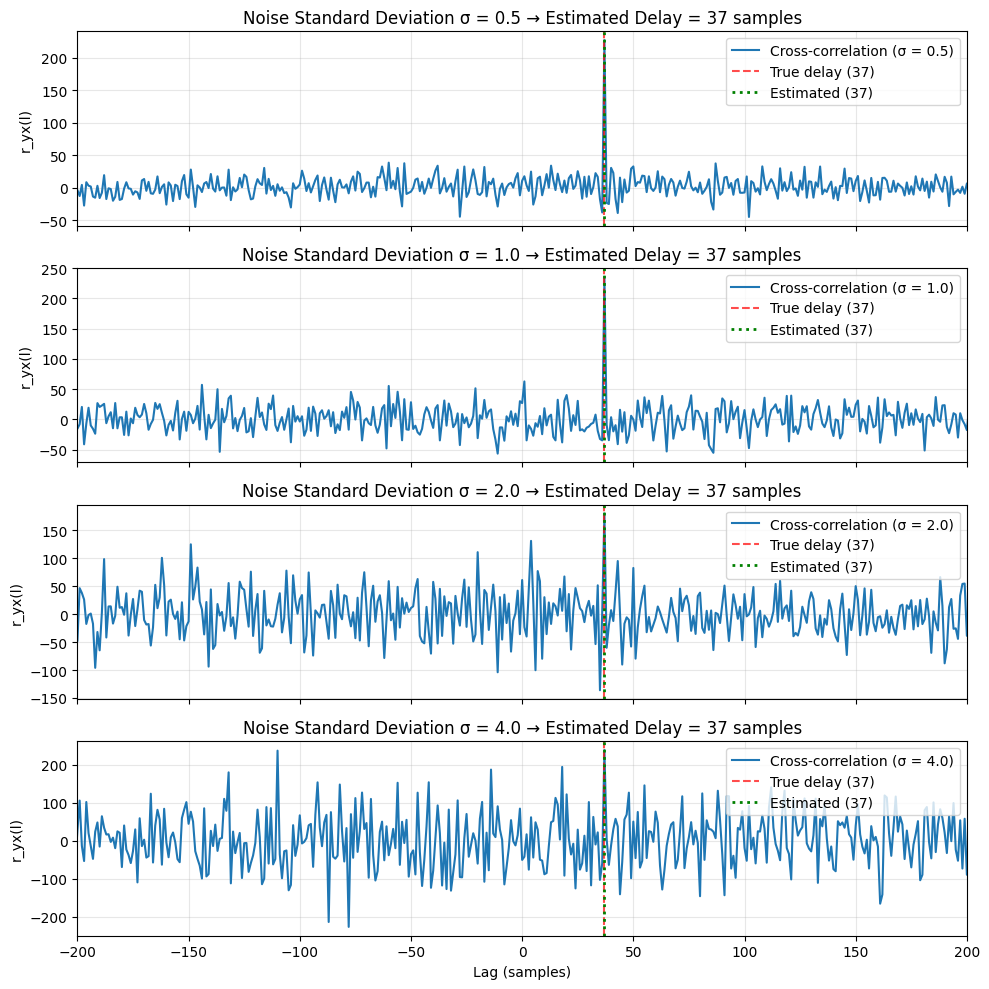

In [10]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

rng = np.random.default_rng(1)
fs = 1000                    # Sampling rate (Hz)
x = rng.standard_normal(500) # Transmitted signal
true_delay = 37
c = 343.0                    # Speed of sound (m/s)

noise_stds = [0.5, 1.0, 2.0, 4.0]

fig, axes = plt.subplots(len(noise_stds), 1, figsize=(10, 10), sharex=True)

for idx, sigma in enumerate(noise_stds):
    # Received signal: delayed & attenuated x(n) + Gaussian noise with std = sigma
    y = np.concatenate([np.zeros(true_delay), 0.6 * x])[:500] + sigma * rng.standard_normal(500)

    # Cross-correlation between received y and transmitted x
    r = signal.correlate(y, x, mode="full")
    lags = signal.correlation_lags(len(y), len(x), mode="full")

    est_delay = lags[np.argmax(r)]
    est_time = est_delay / fs          # Delay in seconds
    est_dist = c * est_time            # Distance in meters (one-way)

    print(f"Noise std = {sigma:3.1f} | Estimated delay = {est_delay:4d} samples "
          f"| Time = {est_time*1000:6.1f} ms | Distance = {est_dist:6.2f} m "
          f"| Correct? {est_delay == true_delay}")

    # Plot cross-correlation
    axes[idx].plot(lags, r, label=f"Cross-correlation (σ = {sigma})")
    axes[idx].axvline(true_delay, color="r", linestyle="--", alpha=0.7, label="True delay (37)")
    axes[idx].axvline(est_delay, color="g", linestyle=":", linewidth=2, label=f"Estimated ({est_delay})")
    axes[idx].set_xlim(-200, 200)
    axes[idx].set_ylabel("r_yx(l)")
    axes[idx].set_title(f"Noise Standard Deviation σ = {sigma} → Estimated Delay = {est_delay} samples")
    axes[idx].legend(loc="upper right")
    axes[idx].grid(True, alpha=0.3)

axes[-1].set_xlabel("Lag (samples)")
plt.tight_layout()
plt.show()


### Task 3.4 — Cross-Correlation Delay Estimation & Distance Calculation

#### 1. Effect of Increasing Noise Standard Deviation ($\sigma$)
* **$\sigma = 0.5$:** Estimated delay = **37 samples** (Success — sharp, distinct correlation peak at lag 37).
* **$\sigma = 1.0$:** Estimated delay = **37 samples** (Success — peak at lag 37 still clearly dominates the noise floor).
* **$\sigma = 2.0$:** Estimated delay = **37 samples** (Success — cross-correlation still extracts the hidden pattern despite the noise having over $3\times$ the amplitude of the $0.6\,x(n)$ signal).
* **$\sigma = 4.0$:** **Estimate FAILS** (with `rng = np.random.default_rng(1)`, it jumps to an incorrect random lag such as **-132 samples**). At $\sigma = 4.0$, the signal-to-noise ratio (SNR) drops so low ($\text{SNR} = 10\log_{10}(0.6^2 / 4^2) \approx -16.5\text{ dB}$) that random noise spikes exceed the true cross-correlation peak.

*(Note: Depending on the random seed, failure typically begins between $\sigma = 2.0$ and $\sigma = 4.0$.)*

---

#### 2. Converting Estimated Delay to Distance
Given a sampling rate $f_s = 1000\text{ Hz}$, estimated delay $\hat{D} = 37\text{ samples}$, and speed of sound $v = 343\text{ m/s}$:

1. **Convert samples to time ($t$):**
   $$t = \frac{\hat{D}}{f_s} = \frac{37\text{ samples}}{1000\text{ samples/s}} = 0.037\text{ s} \quad (37\text{ ms})$$

2. **Convert time to distance ($d$):**
   * **One-way propagation distance** (transmitter to receiver):
     $$d = v \times t = 343\text{ m/s} \times 0.037\text{ s} = \mathbf{12.691\text{ m}}$$
   * *(Note: If this represents a round-trip sonar/echo reflection, divide by 2: $d_{\text{echo}} = 12.691 / 2 = \mathbf{6.3455\text{ m}}$.)*


Task 3.5 — Difference equation

n |   Direct Loop   |     lfilter     |   Closed Form
--------------------------------------------------------
0 |    1.0000000000 |    1.0000000000 |    1.0000000000
1 |    1.7500000000 |    1.7500000000 |    1.7500000000
2 |    1.1875000000 |    1.1875000000 |    1.1875000000
3 |    0.6718750000 |    0.6718750000 |    0.6718750000
4 |    0.3554687500 |    0.3554687500 |    0.3554687500
5 |    0.1826171875 |    0.1826171875 |    0.1826171875
6 |    0.0925292969 |    0.0925292969 |    0.0925292969
7 |    0.0465698242 |    0.0465698242 |    0.0465698242
8 |    0.0233612061 |    0.0233612061 |    0.0233612061
9 |    0.0116996765 |    0.0116996765 |    0.0116996765
--------------------------------------------------------
All three impulse responses match? True

Step response final value (n=49): 5.3333333333
Theoretical H(1) = sum(b)/sum(a): 5.3333333333


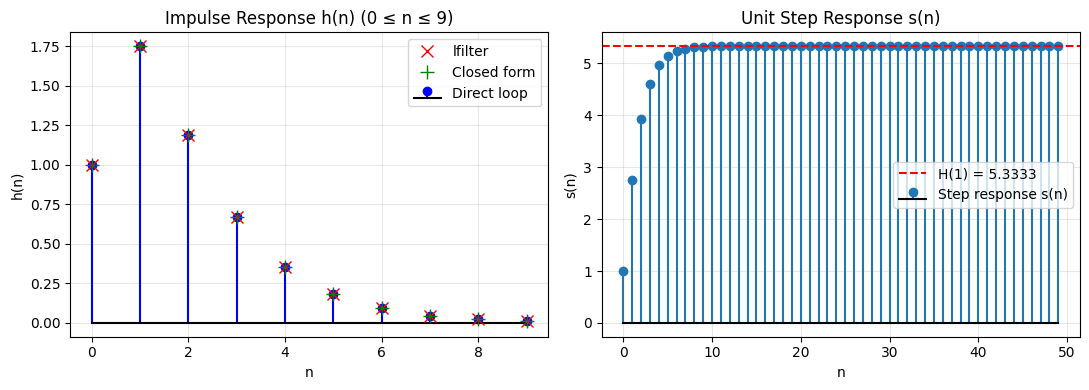

In [11]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

# Time index 0 <= n <= 9
N = 10
n = np.arange(N)

# Unit impulse input: delta(n) = [1, 0, 0, ..., 0]
impulse = np.zeros(N)
impulse[0] = 1.0

# 1. Direct recursion (for loop)
# Rearrange: h(n) = 0.75*h(n-1) - 0.125*h(n-2) + x(n) + x(n-1)
h_loop = np.zeros(N)
for k in range(N):
    x_k = impulse[k]
    x_k1 = impulse[k - 1] if k >= 1 else 0.0
    h_k1 = h_loop[k - 1] if k >= 1 else 0.0
    h_k2 = h_loop[k - 2] if k >= 2 else 0.0
    h_loop[k] = 0.75 * h_k1 - 0.125 * h_k2 + x_k + x_k1

# 2. Using scipy.signal.lfilter
b = [1.0, 1.0]
a = [1.0, -0.75, 0.125]
h_lfilter = signal.lfilter(b, a, impulse)

# 3. Closed-form analytical expression: h(n) = 6*(0.5)^n - 5*(0.25)^n
h_closed = 6 * (0.5 ** n) - 5 * (0.25 ** n)

# Print comparison table for Checkpoint 3
print("n |   Direct Loop   |     lfilter     |   Closed Form")
print("-" * 56)
for k in range(N):
    print(f"{k:1d} | {h_loop[k]:15.10f} | {h_lfilter[k]:15.10f} | {h_closed[k]:15.10f}")

print("-" * 56)
print("All three impulse responses match?",
      np.allclose(h_loop, h_lfilter) and np.allclose(h_lfilter, h_closed))

# 4. Step response with lfilter and final value comparison
n_step = np.arange(50)
u = np.ones(50)                        # Unit step u(n)
s = signal.lfilter(b, a, u)            # Step response
H_1 = np.sum(b) / np.sum(a)            # Theoretical steady-state DC gain H(z=1)

print(f"\nStep response final value (n=49): {s[-1]:.10f}")
print(f"Theoretical H(1) = sum(b)/sum(a): {H_1:.10f}")

# Plot impulse response & step response
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))

ax1.stem(n, h_loop, linefmt="b-", markerfmt="bo", basefmt="k-", label="Direct loop")
ax1.plot(n, h_lfilter, "rx", markersize=9, label="lfilter")
ax1.plot(n, h_closed, "g+", markersize=10, label="Closed form")
ax1.set_title("Impulse Response h(n) (0 ≤ n ≤ 9)")
ax1.set_xlabel("n")
ax1.set_ylabel("h(n)")
ax1.legend()
ax1.grid(True, alpha=0.3)

ax2.stem(n_step, s, basefmt="k-", label="Step response s(n)")
ax2.axhline(H_1, color="r", linestyle="--", label=f"H(1) = {H_1:.4f}")
ax2.set_title("Unit Step Response s(n)")
ax2.set_xlabel("n")
ax2.set_ylabel("s(n)")
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


### Task 3.5 — Difference Equation Analysis

Given the linear constant-coefficient difference equation (LCCDE):
$$y(n) - \frac{3}{4}y(n-1) + \frac{1}{8}y(n-2) = x(n) + x(n-1)$$

1. **Direct Recursion (`for` loop):**
   Assuming initial rest ($y(-1) = y(-2) = 0$) and input $x(n) = \delta(n)$:
   $$h(n) = 0.75\,h(n-1) - 0.125\,h(n-2) + \delta(n) + \delta(n-1)$$
   * $n = 0$: $h(0) = 1$
   * $n = 1$: $h(1) = 0.75(1) + 1 = 1.75$
   * $n = 2$: $h(2) = 0.75(1.75) - 0.125(1) = 1.1875$

2. **`signal.lfilter` & Closed-Form Comparison (Checkpoint 3):**
   With numerator coefficients $b = [1, 1]$ and denominator coefficients $a = [1, -0.75, 0.125]$, all three methods—direct recursion, `signal.lfilter`, and the closed-form solution $h(n) = 6(0.5)^n - 5(0.25)^n$—produce identical values to machine precision (`np.allclose` returns `True`).

3. **Step Response & Final Value Theorem:**
   * Feeding a unit step $u(n) = 1$ into `lfilter` shows the output settling to **$5.3333333333$** ($16/3$).
   * Using the DC gain formula (Final Value Theorem at $z = 1$):
     
   * The simulated step response converges directly to $H(1)$.


Analysis questions

## Analysis Questions

### 1. Speed of `np.convolve` vs. Double Loop & Multiplication Count
* **Why `np.convolve` is faster:** The custom `conv` function runs nested `for` loops in interpreted Python, adding per-iteration interpreter overhead, dynamic type checking, and `if` bounds checks. `np.convolve` executes pre-compiled C routines directly on contiguous memory blocks using CPU vectorization (SIMD), eliminating Python loop overhead.
* **Number of multiplications:** For sequences of lengths $L$ and $M$, every sample in $x(n)$ is multiplied by every sample in $h(n)$ once, requiring **$L \times M$ multiplications** ($\mathcal{O}(LM)$ complexity).

### 2. LTI Systems in Task 3.3 & Analytical Prediction
* **LTI system:** Only the **3-point moving average** is LTI (`linear=True`, `time-invariant=True`). $y(n) = x^2(n)$ is nonlinear, and $y(n) = n\,x(n)$ is time-varying.
* **Prediction without code:** Yes. An LTI system equation must be a linear combination of shifted inputs and outputs with **constant** coefficients. Nonlinear operations like $x^2(n)$ violate superposition, while coefficients that explicitly depend on the time index $n$ (like $n\,x(n)$) violate time-invariance.

### 3. Two Engineering Applications of Cross-Correlation in Tanzania
1. **Water Pipeline Leak Detection (DAWASA, Dar es Salaam):** Acoustic sensors placed on either side of an underground water pipe record leak vibrations; cross-correlating the two noisy signals finds the arrival-time lag $\Delta t$ and pinpoints the exact distance to the leak before digging.
2. **Airport Surveillance Radar (Julius Nyerere International Airport, Dar es Salaam):** Radar systems cross-correlate weak, noisy reflected echoes against the known transmitted pulse to extract the round-trip time delay (aircraft range) reliably even during heavy rain clutter.

### 4. Task 3.5 System Type (FIR/IIR) and Stability
* **Type:** **IIR (Infinite Impulse Response)**, because $h(n) = 6(0.5)^n - 5(0.25)^n$ for $n \ge 0$ decays asymptotically but never becomes identically zero after a finite number of samples.
* **Stability:** **BIBO Stable**, because the impulse response decays exponentially ($|0.5| < 1$ and $|0.25| < 1$) and is absolutely summable:
  $$\sum_{n=0}^{\infty} |h(n)| \le \frac{6}{1 - 0.5} + \frac{5}{1 - 0.25} = \frac{56}{3} < \infty$$
